# HW2 Part 1: Checking and cleaning the price data
inmeng Pan

I use `ohlc_hw` as the input and `ohlc` only for its per-stock session dates and
same-date adjustment factors. I first inspect and diagnose the dirty data, then
apply the documented repairs, compare the results and verify the database write.
The working file below is a copy; the original source should be kept separately.

In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from analysis import (COLUMNS, PRICES, normalize, diagnose, clean_data,
                      clean_database, compare_adjustments, validate_cleaned)

db_path = "data/data.db"
audit_dir = Path("reports") / datetime.now(ZoneInfo("Asia/Shanghai")).strftime("%Y-%m-%d")
audit_dir.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 20)


## 1. Load the source and inspect its columns

| Field | Meaning |
| --- | --- |
| `ts` | Observation date, normalized to a daily timestamp |
| `ticker` | Vendor security label; preserve its original text before normalization |
| `open`, `high`, `low`, `close` | Daily raw OHLC prices, checked against low/high bounds |
| `adj_close` | Vendor-adjusted close; raw OHLC bounds do not apply to this field |
| `volume` | Traded shares; missing volume is distinct from observed zero volume |

The following summaries use all source rows. A preview helps inspect the actual
labels and values, while `info()` and `describe()` check types and distributions.

In [2]:
working_db = Path(db_path).expanduser().resolve()
if not working_db.is_file():
    raise FileNotFoundError(f"Place a local copy of the course database at {working_db}")
with sqlite3.connect(working_db.as_uri() + "?mode=ro", uri=True) as conn:
    display(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", conn))
    raw = pd.read_sql_query("SELECT * FROM ohlc_hw", conn)
    reference = pd.read_sql_query("SELECT * FROM ohlc", conn)
raw.info()
display(raw.head(), raw.tail())
display(raw.describe(include="all").T)
print(f"Rows: {len(raw):,}; original ticker labels: {raw.ticker.nunique()}")
print("Source date range:", raw.ts.min(), "to", raw.ts.max())


,name
0,hw2_quality_after
1,hw2_quality_before
2,market_caps
3,ohlc
4,ohlc_hw
5,ohlc_hw_cleaned
6,ohlc_hw_quarantine
7,reference_calendar


<class 'pandas.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   ts         397711 non-null  str    
 1   open       397711 non-null  float64
 2   high       397711 non-null  float64
 3   low        397711 non-null  float64
 4   close      397711 non-null  float64
 5   adj_close  377856 non-null  float64
 6   volume     397711 non-null  int64  
 7   ticker     397711 non-null  str    
dtypes: float64(5), int64(1), str(2)
memory usage: 24.3 MB


,ts,open,high,low,close,adj_close,volume,ticker
0,1975-04-14,5.4300,5.4800,5.3600,5.4400,1.640000,446392,CAT
1,1978-04-05,4.8400,4.8900,4.8100,4.8800,0.656990,355200,CVX
2,2018-05-25,124.5400,124.7600,121.2200,122.1900,92.220000,8936649,CVX
3,1995-12-07,9.9700,9.9700,9.8300,9.9400,5.880000,3954150,HD
4,1981-07-23,0.1038,0.1038,0.1038,0.1038,0.080013,34451232,AAPL


,ts,open,high,low,close,adj_close,volume,ticker
397706,1999-02-08,23.31,23.66,22.88,23.63,12.25000,3299600,CAT
397707,2010-12-08,25.58,25.84,25.52,25.75,NaN,2077775,SHW
397708,2017-08-28,170.86,172.64,170.26,171.78,139.18000,2359529,AMGN
397709,1990-01-25,1.08,1.10,1.08,1.09,0.77531,17265768,"<a target=""_blank""><span style=""color: blue"">A..."
397710,1992-06-05,11.98,12.14,11.77,12.14,8.98000,11970822,DIS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ts,397711,15868,2020-11-24,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN
open,397711.0,NaN,NaN,NaN,46.285479,67.132594,0.0,4.209938,19.85,57.53,604.26
high,397711.0,NaN,NaN,NaN,46.74766,67.77821,0.005208,4.24,20.06,58.13,608.63
low,397711.0,NaN,NaN,NaN,45.816279,66.477178,0.004801,4.16,19.63,56.95,597.88
close,397711.0,NaN,NaN,NaN,46.292903,67.141879,0.005208,4.2,19.86,57.53,605.4
adj_close,377856.0,NaN,NaN,NaN,51.65225,194.584045,0.002945,1.39,11.96,43.77,10442.510783
volume,397711.0,NaN,NaN,NaN,30977733.689946,126623650.175253,0.0,1730700.0,4648200.0,11023796.5,9276606399.0
ticker,397711,150,PG,15450,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Rows: 397,711; original ticker labels: 150
Source date range: 1962-01-02 to 2024-12-06


## 2. Normalize labels before checking duplicate keys
HTML tags, whitespace and letter case can make the same stock appear to be several
stocks. Grouping returns or removing duplicate keys before this step would give
misleading results. `original_ticker` retains the source label for the audit.

In [3]:
prices = PRICES + ["adj_close"]
normalized = normalize(raw)
normalized_reference = normalize(reference)
label_map = (normalized.groupby(["original_ticker", "ticker"], dropna=False)
             .size().rename("source_rows").reset_index())
label_map.to_csv(audit_dir / "ticker_normalization.csv", index=False)
display(label_map.head(20))
print("Original labels:", len(label_map), "| Normalized tickers:", normalized.ticker.nunique())
print("Normalized stocks:", sorted(normalized.ticker.dropna().unique().tolist()))
coverage = normalized.groupby("ticker").agg(
    source_rows=("ts", "size"), first_date=("ts", "min"), last_date=("ts", "max"))
display(coverage)


,original_ticker,ticker,source_rows
0,"<a target=""_blank""><span style=""color: blue"">A...",AAPL,307
1,"<a target=""_blank""><span style=""color: blue"">A...",AMGN,294
2,"<a target=""_blank""><span style=""color: blue"">A...",AMZN,185
3,"<a target=""_blank""><span style=""color: blue"">A...",AXP,356
4,"<a target=""_blank""><span style=""color: blue"">B...",BA,462
5,"<a target=""_blank""><span style=""color: blue"">C...",CAT,394
6,"<a target=""_blank""><span style=""color: blue"">C...",CRM,129
7,"<a target=""_blank""><span style=""color: blue"">C...",CSCO,230
8,"<a target=""_blank""><span style=""color: blue"">C...",CVX,400
9,"<a target=""_blank""><span style=""color: blue"">D...",DIS,458


Original labels: 150 | Normalized tickers: 30
Normalized stocks: ['AAPL', 'AMGN', 'AMZN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'GS', 'HD', 'HON', 'IBM', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'NVDA', 'PG', 'SHW', 'TRV', 'UNH', 'V', 'VZ', 'WMT']


,source_rows,first_date,last_date
ticker,,,
AAPL,11942,1980-12-12,2024-10-18
AMGN,11290,1983-06-17,2024-10-18
AMZN,7458,1997-05-15,2024-12-06
AXP,14260,1972-04-03,2024-10-18
BA,16980,1962-01-02,2024-10-18
CAT,17044,1962-01-02,2024-10-18
CRM,5525,2004-06-23,2024-10-18
CSCO,9427,1990-02-16,2024-10-18
CVX,17073,1962-01-02,2024-12-06


In [4]:
duplicate_rows = normalized.duplicated(COLUMNS, keep=False)
exact_removals = normalized.duplicated(COLUMNS).sum()
unique_records = normalized.drop_duplicates(COLUMNS)
conflicts = unique_records.loc[unique_records.duplicated(["ticker", "ts"], keep=False)]
display(pd.Series({"rows_in_duplicate_groups": int(duplicate_rows.sum()),
                   "exact_copies_to_remove": int(exact_removals),
                   "conflicting_price_rows": len(conflicts)}).to_frame("rows"))
display(normalized.loc[duplicate_rows, ["ticker", "original_ticker", "ts", "close", "adj_close"]].head(12))
if not conflicts.empty:
    display(conflicts.head(10))


,rows
rows_in_duplicate_groups,58920
exact_copies_to_remove,29460
conflicting_price_rows,0


,ticker,original_ticker,ts,close,adj_close
13,AAPL,AAPL,1981-01-02,0.15402,0.118730
14,AAPL,AAPL,1981-01-02,0.15402,0.118730
15,AAPL,AAPL,1981-01-05,0.15067,0.116150
16,AAPL,AAPL,1981-01-05,0.15067,0.116150
42,AAPL,AAPL,1981-02-10,0.12165,0.093779
43,AAPL,AAPL,1981-02-10,0.12165,0.093779
55,AAPL,AAPL,1981-02-27,0.11830,0.091197
56,AAPL,AAPL,1981-02-27,0.11830,0.091197
60,AAPL,AAPL,1981-03-05,0.11551,0.089046
61,AAPL,AAPL,1981-03-05,0.11551,0.089046


## 3. Record problems before making repairs
The quality report has one row per failed rule, so one observation can have several
issues. High severity marks invalid prices/keys or adjustment disagreements;
medium covers missing data, duplicates and statistical review; low marks label
normalization or zero-volume review. Severity does not automatically imply deletion.

In [5]:
quality_before = diagnose(normalized, normalized_reference)
issue_counts_before = (quality_before.groupby(["issue_type", "severity"])
                       .size().rename("issues").reset_index())
display(issue_counts_before)
display(quality_before.head(15))
quality_before.to_csv(audit_dir / "data_quality_before.csv", index=False)


,issue_type,severity,issues
0,adjustment_mismatch,high,11265
1,duplicate_record,medium,58920
2,invalid_value,high,5
3,missing_value,high,19855
4,price_bounds,high,5
5,return_outlier,medium,5741
6,ticker_normalized,low,39936
7,zero_volume,low,81


,ticker,issue_type,issue_date,description,severity
0,AAPL,adjustment_mismatch,1981-02-03,Adjusted close disagrees with the independent ...,high
1,AAPL,adjustment_mismatch,1981-04-28,Adjusted close disagrees with the independent ...,high
2,AAPL,adjustment_mismatch,1981-05-08,Adjusted close disagrees with the independent ...,high
3,AAPL,adjustment_mismatch,1981-07-29,Adjusted close disagrees with the independent ...,high
4,AAPL,adjustment_mismatch,1981-08-06,Adjusted close disagrees with the independent ...,high
5,AAPL,adjustment_mismatch,1981-08-13,Adjusted close disagrees with the independent ...,high
6,AAPL,adjustment_mismatch,1981-08-13,Adjusted close disagrees with the independent ...,high
7,AAPL,adjustment_mismatch,1981-08-14,Adjusted close disagrees with the independent ...,high
8,AAPL,adjustment_mismatch,1981-10-08,Adjusted close disagrees with the independent ...,high
9,AAPL,adjustment_mismatch,1981-12-31,Adjusted close disagrees with the independent ...,high


### Missing cells versus missing observations
Null cells already have a row; an absent session has no row at all. I use each
stock's supplied `ohlc` dates, not business weekdays that would include holidays.
The check can report zero gaps. Expected and observed date counts are shown below;
the small test section later removes a date deliberately to verify the detector.

In [6]:
missing_cells = raw[COLUMNS].isna().sum().to_frame("missing_cells")
missing_cells["share_of_rows"] = missing_cells["missing_cells"] / len(raw)
display(missing_cells)
gaps = quality_before.loc[quality_before.issue_type.eq("missing_trading_day")]
calendar_rows = []
for ticker, group in normalized.groupby("ticker"):
    expected = pd.DatetimeIndex(normalized_reference.loc[normalized_reference.ticker.eq(ticker), "ts"].dropna().unique())
    observed = pd.DatetimeIndex(group.ts.dropna().unique())
    absent = expected.difference(observed)
    calendar_rows.append({"ticker": ticker, "expected_sessions": len(expected),
                          "observed_dates": len(observed), "missing_sessions": len(absent),
                          "first_reference_date": expected.min(), "last_reference_date": expected.max()})
calendar_check = pd.DataFrame(calendar_rows)
display(calendar_check)
calendar_check.to_csv(audit_dir / "calendar_check_before.csv", index=False)
print("Missing reference sessions before cleaning:", len(gaps))


,missing_cells,share_of_rows
ts,0,0.000000
ticker,0,0.000000
open,0,0.000000
high,0,0.000000
low,0,0.000000
close,0,0.000000
adj_close,19855,0.049923
volume,0,0.000000


,ticker,expected_sessions,observed_dates,missing_sessions,first_reference_date,last_reference_date
0,AAPL,11050,11050,0,1980-12-12,2024-10-18
1,AMGN,10421,10421,0,1983-06-17,2024-10-18
2,AMZN,6937,6937,0,1997-05-15,2024-12-06
3,AXP,13252,13252,0,1972-04-03,2024-10-18
4,BA,15784,15784,0,1962-01-02,2024-10-18
5,CAT,15808,15808,0,1962-01-02,2024-10-18
6,CRM,5117,5117,0,2004-06-23,2024-10-18
7,CSCO,8734,8734,0,1990-02-16,2024-10-18
8,CVX,15843,15843,0,1962-01-02,2024-12-06
9,DIS,15867,15867,0,1962-01-02,2024-12-06


Missing reference sessions before cleaning: 0


### Nonpositive prices, impossible raw bounds and zero volume
Adjusted prices are checked for positivity and finiteness separately from raw OHLC
bounds. Zero volume is retained as a review flag; it may be genuine and does not
justify inventing trading activity. The rows below show the actual problematic bars.

In [7]:
invalid_price = (~np.isfinite(normalized[prices]) | normalized[prices].le(0)).any(axis=1)
bad_bounds = (normalized.low.gt(normalized.high)
              | normalized.open.lt(normalized.low) | normalized.open.gt(normalized.high)
              | normalized.close.lt(normalized.low) | normalized.close.gt(normalized.high))
display(normalized.loc[invalid_price | bad_bounds, COLUMNS].head(15))
zero_volume = normalized.loc[normalized.volume.eq(0)]
print("Invalid or missing price rows:", int(invalid_price.sum()))
print("Invalid raw-bound rows:", int(bad_bounds.sum()))
print("Zero-volume source observations:", len(zero_volume))
display(zero_volume[["ticker", "ts", "close", "volume"]].head(10))


,ts,ticker,open,high,low,close,adj_close,volume
19,1981-01-08,AAPL,0.135050,0.135050,0.135050,0.135050,NaN,39827236
22,1981-01-13,AAPL,0.136160,0.136160,0.136160,0.136160,NaN,23049620
45,1981-02-12,AAPL,0.116630,0.116630,0.116630,0.116630,NaN,14560012
96,1981-04-16,AAPL,0.111610,0.111610,0.111610,0.111610,NaN,23878420
119,1981-05-19,AAPL,0.122770,0.122770,0.122770,0.122770,NaN,25424024
131,1981-06-04,AAPL,0.143410,0.143410,0.143410,0.143410,NaN,56067255
161,1981-07-14,AAPL,0.106030,0.106030,0.106030,0.106030,NaN,19779216
165,1981-07-20,AAPL,0.107700,0.107700,0.107700,0.107700,NaN,23654420
195,1981-08-26,AAPL,0.084821,0.084821,0.084821,0.084821,NaN,33600032
239,1981-10-23,AAPL,0.084821,0.084821,0.084821,0.084821,NaN,27910424


Invalid or missing price rows: 19860
Invalid raw-bound rows: 5
Zero-volume source observations: 81


,ticker,ts,close,volume
30876,AXP,1972-12-14,4.01000,0
30877,AXP,1972-12-14,4.01000,0
152443,HON,1982-09-23,5.54000,0
152444,HON,1982-09-24,5.54000,0
167090,IBM,1973-10-09,15.64000,0
167445,IBM,1975-01-27,9.73000,0
169347,IBM,1982-01-08,13.56000,0
181061,JNJ,1962-01-02,0.22338,0
181138,JNJ,1962-04-17,0.21875,0
181265,JNJ,1962-09-28,0.15914,0


### Statistical return outliers are review flags
The assignment's screen uses simple raw-close returns, the per-ticker mean and
sample standard deviation (`ddof=1`), and flags both tails at more than three
standard deviations. Repeated dirty records can affect these statistics, so the
screen is rerun after deduplication/repair. No split, merger or news explanation
is claimed without supporting evidence; valid extreme moves remain in the data.

In [8]:
return_review = normalized.copy()
return_review["simple_return"] = return_review.groupby("ticker").close.pct_change(fill_method=None)
return_review["simple_return"] = return_review.simple_return.replace([np.inf, -np.inf], np.nan)
by_stock = return_review.groupby("ticker").simple_return
return_review["mean_return"] = by_stock.transform("mean")
return_review["sample_std"] = by_stock.transform("std")
flag = (return_review.sample_std.gt(0)
        & (return_review.simple_return - return_review.mean_return).abs().gt(3 * return_review.sample_std))
display(return_review.loc[flag, ["ticker", "ts", "close", "simple_return", "mean_return", "sample_std"]]
        .sort_values("simple_return", key=lambda x: x.abs(), ascending=False).head(15))
print("Pre-repair statistical review flags:", int(flag.sum()))


,ticker,ts,close,simple_return,mean_return,sample_std
343765,TRV,1976-10-28,9.220000,1.000000,0.000530,0.023304
345085,TRV,1981-08-10,12.060000,1.000000,0.000530,0.023304
344353,TRV,1978-12-20,8.030000,0.997512,0.000530,0.023304
230852,MCD,1968-01-02,0.174900,-0.753620,0.000629,0.017835
5419,AAPL,2000-09-29,0.459820,-0.518695,0.000994,0.026787
345086,TRV,1981-08-11,6.030000,-0.500000,0.000530,0.023304
343766,TRV,1976-10-29,4.690000,-0.491323,0.000530,0.023304
344354,TRV,1978-12-21,4.090000,-0.490660,0.000530,0.023304
303210,NVDA,2000-03-07,0.173570,0.424106,0.001812,0.036365
304410,NVDA,2004-08-06,0.078584,-0.352314,0.001812,0.036365


Pre-repair statistical review flags: 5741


### Compare adjusted close with an independent same-date factor
An adjusted close can be positive yet inconsistent with the reference adjustment
convention. For each unambiguous reference key, compare the vendor value with
`dirty close × (reference adj_close / reference close)`. Missing adjusted values
are diagnosed separately. The comparison uses `rtol=1e-5` and does not forward-fill
factors across possible corporate actions. Examples make the needed repair visible.

In [9]:
adjustment_check = compare_adjustments(normalized, normalized_reference)
mismatch_examples = adjustment_check.loc[adjustment_check.factor_mismatch,
    ["ticker", "ts", "close", "adj_close", "factor", "expected_adj_close"]]
print("Positive adjusted closes inconsistent with the reference:", len(mismatch_examples))
display(mismatch_examples.head(15))
mismatch_examples.head(50).to_csv(audit_dir / "adjustment_mismatch_examples.csv", index=False)


Positive adjusted closes inconsistent with the reference: 11265


,ticker,ts,close,adj_close,factor,expected_adj_close
37,AAPL,1981-02-03,0.123330,1.264587,0.770853,0.095069
104,AAPL,1981-04-28,0.126120,2.036653,0.770854,0.097220
112,AAPL,1981-05-08,0.125000,2.129290,0.770878,0.096360
174,AAPL,1981-07-29,0.106030,0.506329,0.770857,0.081734
180,AAPL,1981-08-06,0.112720,2.009828,0.770899,0.086896
184,AAPL,1981-08-13,0.103800,1.122224,0.770841,0.080013
185,AAPL,1981-08-13,0.103800,1.122224,0.770841,0.080013
186,AAPL,1981-08-14,0.102120,1.171347,0.770878,0.078722
228,AAPL,1981-10-08,0.082589,1.245215,0.770878,0.063666
289,AAPL,1981-12-31,0.098772,1.730921,0.770878,0.076141


## 4. Test rules that the actual file may not exercise
These small, deliberately damaged examples are separate from the real source.
They check a removed session, missing prices/volume, bad bounds, conflicting keys,
leading gaps, same-date factor requirements and both tails of the return screen.

In [10]:
days = pd.to_datetime(["2024-01-02", "2024-01-03", "2024-01-04", "2024-01-05",
                       "2024-01-08", "2024-01-09", "2024-01-10", "2024-01-11",
                       "2024-01-12", "2024-01-16"])
reference_example = pd.DataFrame({"ts": days, "ticker": "AAA", "open": 100.,
    "high": 102., "low": 98., "close": 100., "adj_close": 50., "volume": 1000.})
dirty_example = reference_example.drop(index=1).copy()
dirty_example.loc[0, ["open", "adj_close"]] = np.nan
dirty_example.loc[2, "close"] = np.nan
dirty_example.loc[3, "volume"] = np.nan
dirty_example.loc[4, "high"] = 90
dirty_example.loc[5, ["open", "high", "low", "close"]] = np.nan
dirty_example.loc[6, "close"] = -1
dirty_example.loc[7, "volume"] = np.inf
dirty_example.loc[8, "adj_close"] = np.nan
dirty_example.loc[9, "volume"] = 0
dirty_example["ticker"] = " <b>aaa</b> "
dirty_example = pd.concat([dirty_example, dirty_example.iloc[[2]]], ignore_index=True)
conflict = reference_example.iloc[[9]].copy()
conflict["volume"] = 99
dirty_example = pd.concat([dirty_example, conflict], ignore_index=True)

demo_cleaned, demo_quarantine, demo_before, demo_after, demo_counts = clean_data(
    dirty_example, reference_example)
display(demo_before, demo_counts.to_frame(), demo_cleaned, demo_quarantine)
assert "missing_trading_day" in set(demo_before.issue_type)
assert "price_bounds" in set(demo_before.issue_type)
assert "conflicting_key" in set(demo_before.issue_type)
assert demo_counts["exact_duplicates_removed"] == 1
assert demo_cleaned.filled_close.any()
assert demo_cleaned.volume_unknown.any()
assert demo_cleaned.adjustment_rebuilt.any()
assert "invalid_value" not in set(demo_after.issue_type)
print("Injected cleaning checks passed.")


,ticker,issue_type,issue_date,description,severity
0,AAA,missing_value,2024-01-02,Missing open,high
1,AAA,missing_value,2024-01-09,Missing open,high
2,AAA,missing_value,2024-01-09,Missing high,high
3,AAA,missing_value,2024-01-09,Missing low,high
4,AAA,missing_value,2024-01-04,Missing close,high
5,AAA,missing_value,2024-01-09,Missing close,high
6,AAA,invalid_value,2024-01-10,Nonfinite or invalid close,high
7,AAA,missing_value,2024-01-02,Missing adj_close,high
8,AAA,missing_value,2024-01-12,Missing adj_close,high
9,AAA,missing_value,2024-01-05,Missing volume,medium


,rows
input,11
exact_duplicates_removed,1
all_raw_missing_removed,1
retained,3
quarantined,6


,ts,ticker,open,high,low,close,adj_close,volume,original_ticker,filled_open,filled_high,filled_low,filled_close,volume_unknown,adjustment_rebuilt,return_outlier,outlier_review
0,2024-01-04,AAA,100.0,102.0,98.0,100.0,50.0,1000.0,<b>aaa</b>,False,False,False,True,False,True,False,
1,2024-01-05,AAA,100.0,102.0,98.0,100.0,50.0,0.0,<b>aaa</b>,False,False,False,False,True,False,False,
2,2024-01-12,AAA,100.0,102.0,98.0,100.0,50.0,1000.0,<b>aaa</b>,False,False,False,False,False,True,False,


,ts,ticker,open,high,low,close,adj_close,volume,original_ticker,quarantine_reason,factor,filled_open,filled_high,filled_low,filled_close,volume_unknown,adjustment_rebuilt
0,2024-01-16,AAA,100.0,102.0,98.0,100.0,50.0,0.0,<b>aaa</b>,Conflicting ticker/date records; no arbitrary ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2024-01-16,AAA,100.0,102.0,98.0,100.0,50.0,99.0,AAA,Conflicting ticker/date records; no arbitrary ...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-01-02,AAA,NaN,102.0,98.0,100.0,50.0,1000.0,<b>aaa</b>,"Unresolved prices, OHLC bounds, or invalid vol...",0.5,True,False,False,False,False,True
3,2024-01-08,AAA,100.0,90.0,98.0,100.0,50.0,1000.0,<b>aaa</b>,"Unresolved prices, OHLC bounds, or invalid vol...",0.5,False,False,False,False,False,False
4,2024-01-10,AAA,100.0,102.0,98.0,-1.0,-0.5,1000.0,<b>aaa</b>,"Unresolved prices, OHLC bounds, or invalid vol...",0.5,False,False,False,False,False,True
5,2024-01-11,AAA,100.0,102.0,98.0,100.0,50.0,inf,<b>aaa</b>,"Unresolved prices, OHLC bounds, or invalid vol...",0.5,False,False,False,False,False,False


Injected cleaning checks passed.


In [11]:
# The same date may have several diagnostics; a zero count is also a valid result.
gap_example = normalize(reference_example.drop(index=1))
gaps = diagnose(gap_example, normalize(reference_example))
assert len(gaps[gaps.issue_type.eq("missing_trading_day")]) == 1
assert diagnose(normalize(reference_example), normalize(reference_example)).empty

# Leading missing close has no earlier value and must not borrow another ticker's price.
leading = reference_example.iloc[:2].copy()
leading.loc[0, "close"] = np.nan
kept, rejected, *_ = clean_data(leading, reference_example.iloc[:2])
assert len(rejected) == 1 and len(kept) == 1

# A repaired close cannot use an adjustment factor from another date.
no_factor = reference_example.iloc[:2].copy()
no_factor.loc[1, "close"] = np.nan
kept, rejected, *_ = clean_data(no_factor, reference_example.iloc[:1])
assert len(rejected) == 1

# Zero standard deviation gives no return outliers; both tails of long histories work.
from analysis import return_outliers
test_returns = np.zeros(101)
test_returns[30], test_returns[70] = .5, -.5
screen = pd.DataFrame({"ticker": "TEST", "close": 100 * np.cumprod(1 + test_returns)})
assert return_outliers(screen).iloc[[30, 70]].all()
assert not return_outliers(pd.DataFrame({"ticker": ["TEST"] * 5, "close": [100.] * 5})).any()
print("Calendar, leading-gap, adjustment and two-tailed outlier checks passed.")


Calendar, leading-gap, adjustment and two-tailed outlier checks passed.


## 5. Apply the cleaning policy

| Situation | Action |
| --- | --- |
| Identical normalized rows | Remove repeated copies, retain one price observation |
| Conflicting ticker/date records | Quarantine every candidate; do not choose a winner |
| All raw OHLC missing | Remove before filling |
| Missing raw price | Forward-fill only within a sorted ticker, then recheck bounds |
| Missing volume | Fill with zero and retain the unknown-volume flag |
| Missing/inconsistent adjusted close | Reconstruct only with a valid independent same-date factor |
| Unresolved invalid prices, raw bounds or volume | Quarantine with a reason |
| Extreme but valid return | Keep with an uncertainty/review flag |

`clean_database` reuses the tested functions in `analysis.py`, writes the cleaned and
audit tables to the working copy, and leaves the three source tables unchanged.

In [12]:
raw, reference, cleaned, quarantined, saved_before, quality_after, accounting = clean_database(db_path)
assert len(saved_before) == len(quality_before)
quality_before = saved_before
display(accounting.to_frame())
assert accounting["input"] == sum(accounting[key] for key in
    ["retained", "exact_duplicates_removed", "all_raw_missing_removed", "quarantined"])
repair_columns = ["filled_open", "filled_high", "filled_low", "filled_close",
                  "volume_unknown", "adjustment_rebuilt"]
repair_counts = cleaned[repair_columns].sum().rename("retained_rows_with_flag").to_frame()
display(repair_counts)
repair_counts.to_csv(audit_dir / "repair_counts.csv")
print("Quarantine reasons:")
display(quarantined.groupby("quarantine_reason").size().rename("rows").to_frame())
display(quarantined[COLUMNS + ["quarantine_reason"]])
quarantined.to_csv(audit_dir / "quarantined_rows.csv", index=False)


,rows
input,397711
exact_duplicates_removed,29460
all_raw_missing_removed,0
retained,368246
quarantined,5


,retained_rows_with_flag
filled_open,0
filled_high,0
filled_low,0
filled_close,0
volume_unknown,0
adjustment_rebuilt,28791


Quarantine reasons:


,rows
quarantine_reason,
"Unresolved prices, OHLC bounds, or invalid volume after filling",5


,ts,ticker,open,high,low,close,adj_close,volume,quarantine_reason
0,1962-01-02,CVX,0.0,3.30000,3.24000,3.30000,0.335750,105840,"Unresolved prices, OHLC bounds, or invalid vol..."
1,1962-01-02,JNJ,0.0,0.22338,0.22222,0.22338,0.064012,0,"Unresolved prices, OHLC bounds, or invalid vol..."
2,1966-07-05,MCD,0.0,0.27366,0.26749,0.26955,0.118090,388800,"Unresolved prices, OHLC bounds, or invalid vol..."
3,1962-01-02,MRK,0.0,0.39703,0.39317,0.39537,0.068447,633830,"Unresolved prices, OHLC bounds, or invalid vol..."
4,1962-01-02,PG,0.0,1.44000,1.42000,1.43000,0.259300,192000,"Unresolved prices, OHLC bounds, or invalid vol..."


## 6. Compare repairs with the original observations
Deduplicating before a one-to-one comparison prevents repeated source rows from
inflating repair counts. A reconstructed value can differ even when the original
adjusted price was nonmissing; those are convention mismatches, not null fills.

In [13]:
source_unique = normalized.drop_duplicates(COLUMNS)
source_unique = source_unique.loc[~source_unique.duplicated(["ticker", "ts"], keep=False)]
changes = cleaned[["ticker", "ts", "close", "adj_close", "adjustment_rebuilt"]].merge(
    source_unique[["ticker", "ts", "adj_close"]].rename(columns={"adj_close": "original_adj_close"}),
    on=["ticker", "ts"], validate="one_to_one")
repaired_examples = changes.loc[changes.adjustment_rebuilt].copy()
repaired_examples["repair_kind"] = np.where(repaired_examples.original_adj_close.isna(),
                                           "missing adjusted close", "reference-factor disagreement")
display(repaired_examples.groupby("repair_kind").size().rename("rows").to_frame())
display(repaired_examples.groupby("repair_kind", group_keys=False).head(8))
repaired_examples.groupby("repair_kind", group_keys=False).head(15).to_csv(
    audit_dir / "adjustment_repair_examples.csv", index=False)

def price_summary(frame, stage):
    result = frame[prices].agg(["count", "mean", "median", "min", "max"]).T
    result["missing"] = frame[prices].isna().sum()
    result["stage"] = stage
    return result.rename_axis("price_column").reset_index()

before_after = pd.concat([price_summary(normalized, "before"), price_summary(cleaned, "after")], ignore_index=True)
display(before_after)
before_after.to_csv(audit_dir / "price_statistics_before_after.csv", index=False)


,rows
repair_kind,
missing adjusted close,18374
reference-factor disagreement,10417


,ticker,ts,close,adj_close,adjustment_rebuilt,original_adj_close,repair_kind
17,AAPL,1981-01-08,0.135050,0.104100,True,NaN,missing adjusted close
20,AAPL,1981-01-13,0.136160,0.104960,True,NaN,missing adjusted close
35,AAPL,1981-02-03,0.123330,0.095069,True,1.264587,reference-factor disagreement
42,AAPL,1981-02-12,0.116630,0.089907,True,NaN,missing adjusted close
86,AAPL,1981-04-16,0.111610,0.086035,True,NaN,missing adjusted close
93,AAPL,1981-04-28,0.126120,0.097220,True,2.036653,reference-factor disagreement
101,AAPL,1981-05-08,0.125000,0.096360,True,2.129290,reference-factor disagreement
108,AAPL,1981-05-19,0.122770,0.094639,True,NaN,missing adjusted close
119,AAPL,1981-06-04,0.143410,0.110560,True,NaN,missing adjusted close
146,AAPL,1981-07-14,0.106030,0.081734,True,NaN,missing adjusted close


,price_column,count,mean,median,min,max,missing,stage
0,open,397711.0,46.285479,19.85,0.000000,604.260000,0,before
1,high,397711.0,46.747660,20.06,0.005208,608.630000,0,before
2,low,397711.0,45.816279,19.63,0.004801,597.880000,0,before
3,close,397711.0,46.292903,19.86,0.005208,605.400000,0,before
4,adj_close,377856.0,51.652250,11.96,0.002945,10442.510783,19855,before
5,open,368246.0,46.309394,19.89,0.005208,604.260000,0,after
6,high,368246.0,46.771824,20.09,0.005208,608.630000,0,after
7,low,368246.0,45.840375,19.67,0.004801,597.880000,0,after
8,close,368246.0,46.317325,19.91,0.005208,605.400000,0,after
9,adj_close,368246.0,37.274670,11.46,0.002945,605.400000,0,after


## 7. Validate values, keys, dates and adjustment consistency
The five checks below cover all retained rows rather than a preview. A row can pass
raw OHLC bounds while still having a bad adjusted price, so these checks are separate.

In [14]:
validate_cleaned(cleaned)
final_adjustments = compare_adjustments(cleaned, normalized_reference)
assert not final_adjustments.factor_mismatch.any()
reconstructed = final_adjustments.loc[final_adjustments.adjustment_rebuilt]
assert reconstructed.factor.notna().all()
np.testing.assert_allclose(reconstructed.adj_close, reconstructed.expected_adj_close, rtol=1e-12)
assert not cleaned.duplicated(["ticker", "ts"]).any()
iso_dates = cleaned.ts.dt.strftime("%Y-%m-%d")
assert iso_dates.str.fullmatch(r"\d{4}-\d{2}-\d{2}").all()
print(f"All {len(cleaned):,} retained rows passed price, volume, key and date checks.")
print(f"All {len(reconstructed):,} reconstructed adjusted closes match their date-specific factors.")
after_counts = quality_after.groupby(["issue_type", "severity"]).size().rename("issues").reset_index()
display(after_counts)
quality_after.to_csv(audit_dir / "data_quality_after.csv", index=False)
print("Remaining missing reference dates:")
display(quality_after.loc[quality_after.issue_type.eq("missing_trading_day")])


All 368,246 retained rows passed price, volume, key and date checks.
All 28,791 reconstructed adjusted closes match their date-specific factors.


,issue_type,severity,issues
0,missing_trading_day,medium,5
1,return_outlier,medium,5057
2,ticker_normalized,low,36985
3,zero_volume,low,74


Remaining missing reference dates:


,ticker,issue_type,issue_date,description,severity
42116,CVX,missing_trading_day,1962-01-02,Missing supplied-calendar session within obser...,medium
42117,JNJ,missing_trading_day,1962-01-02,Missing supplied-calendar session within obser...,medium
42118,MCD,missing_trading_day,1966-07-05,Missing supplied-calendar session within obser...,medium
42119,MRK,missing_trading_day,1962-01-02,Missing supplied-calendar session within obser...,medium
42120,PG,missing_trading_day,1962-01-02,Missing supplied-calendar session within obser...,medium


### Read the database back and verify persistence
Validation is repeated on the saved table. Source-table equality also checks values
and row order, not just counts, so a successful write is not mistaken for preserving
the original data. Output rows use ISO date strings for the report's SQL filters.

In [15]:
with sqlite3.connect(working_db.as_uri() + "?mode=ro", uri=True) as conn:
    persisted = pd.read_sql_query("SELECT * FROM ohlc_hw_cleaned ORDER BY ticker, ts", conn)
    raw_after_write = pd.read_sql_query("SELECT * FROM ohlc_hw", conn)
    reference_after_write = pd.read_sql_query("SELECT * FROM ohlc", conn)
validate_cleaned(normalize(persisted))
pd.testing.assert_frame_equal(raw, raw_after_write)
pd.testing.assert_frame_equal(reference, reference_after_write)
expected_saved = cleaned[["ticker", "ts"] + prices + ["volume"]].copy()
expected_saved["ts"] = expected_saved.ts.dt.strftime("%Y-%m-%d")
pd.testing.assert_frame_equal(expected_saved.reset_index(drop=True),
    persisted[["ticker", "ts"] + prices + ["volume"]].reset_index(drop=True), check_dtype=False)
print(f"Read back {len(persisted):,} rows; values match and original raw/reference tables are unchanged.")


Read back 368,246 rows; values match and original raw/reference tables are unchanged.


## 8. Visual review
Issue bars count diagnoses, not rejected rows: one observation can appear more than
once. Missing adjusted prices and reference-factor mismatches are shown separately.
The second chart compares the raw and repaired adjusted-price history around one
actual mismatch, using a deduplicated source series. Breaks remain missing; the chart
does not replace the value-level validation above.

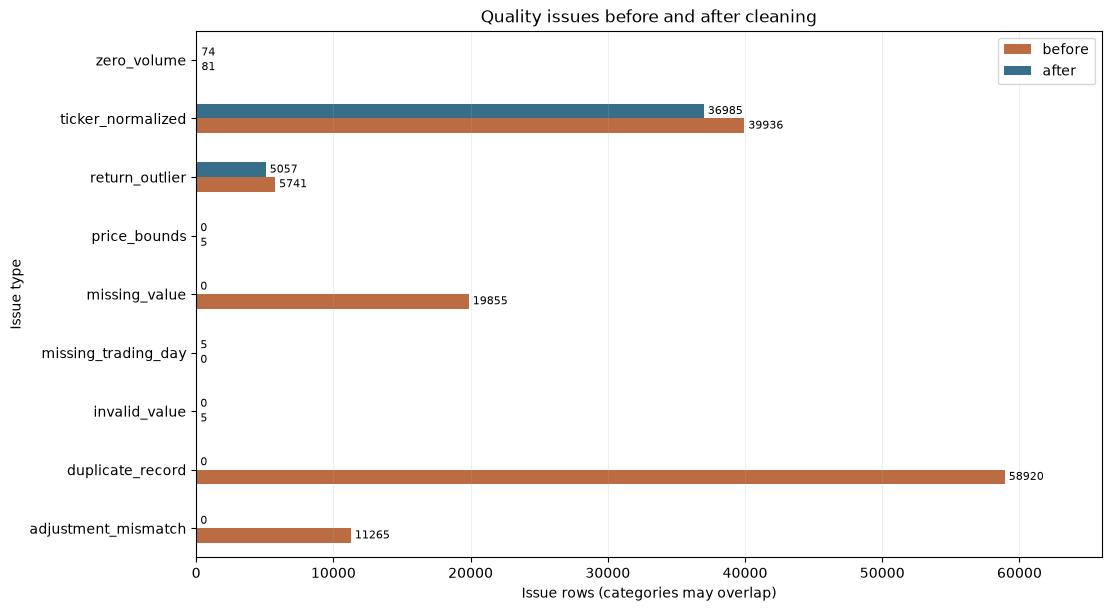

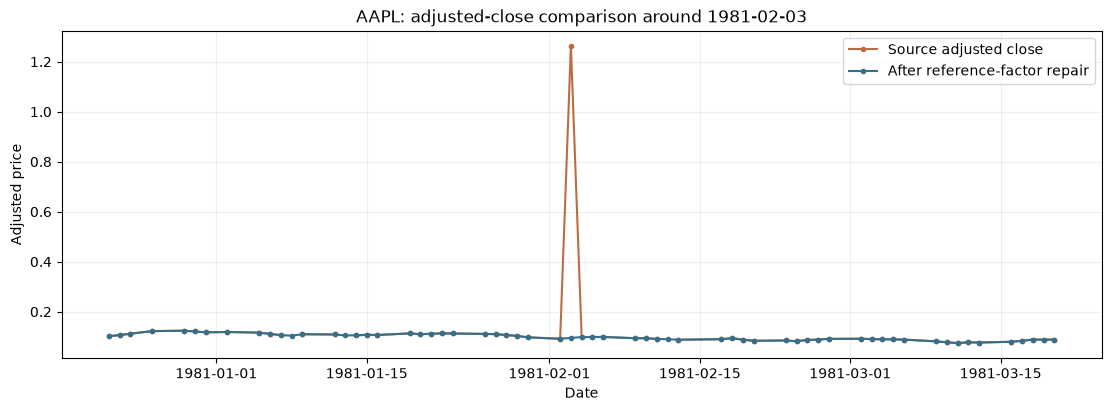

In [16]:
before_counts = quality_before.groupby("issue_type").size()
after_counts = quality_after.groupby("issue_type").size()
issue_comparison = pd.concat([before_counts.rename("before"), after_counts.rename("after")], axis=1).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(11, 6), layout="constrained")
issue_comparison.sort_index().plot.barh(ax=ax, color=["#bb6c42", "#376f8a"])
ax.set(title="Quality issues before and after cleaning", xlabel="Issue rows (categories may overlap)", ylabel="Issue type")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%d", padding=3, fontsize=8)
ax.margins(x=.12)
ax.grid(axis="x", alpha=.2)
display(fig)
fig.savefig(audit_dir / "cleaning_issue_comparison.png", dpi=150)
plt.close(fig)

example = mismatch_examples.iloc[0]
window_start, window_end = example.ts - pd.Timedelta(days=45), example.ts + pd.Timedelta(days=45)
old_prices = source_unique.loc[source_unique.ticker.eq(example.ticker) & source_unique.ts.between(window_start, window_end)]
new_prices = cleaned.loc[cleaned.ticker.eq(example.ticker) & cleaned.ts.between(window_start, window_end)]
fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
ax.plot(old_prices.ts, old_prices.adj_close, color="#bb6c42", marker=".", label="Source adjusted close")
ax.plot(new_prices.ts, new_prices.adj_close, color="#376f8a", marker=".", label="After reference-factor repair")
ax.set(title=f"{example.ticker}: adjusted-close comparison around {example.ts.date()}", xlabel="Date", ylabel="Adjusted price")
ax.legend()
ax.grid(alpha=.2)
display(fig)
fig.savefig(audit_dir / "adjustment_repair_comparison.png", dpi=150)
plt.close(fig)


## 9. Findings and handoff to the report notebook
The following summary is calculated from this execution. Review flags remain visible:
zero-volume days or unusually large moves are not silently erased to make the output
look clean. The stock report uses adjusted close and discloses actual coverage rather
than extrapolating every ticker to the common requested end date.

In [17]:
missing_adj_before = int(raw.adj_close.isna().sum())
pre_mismatches = int(adjustment_check.factor_mismatch.sum())
post_outliers = int(cleaned.return_outlier.sum())
post_zero_volume = int(cleaned.volume.eq(0).sum())
post_missing = int(quality_after.issue_type.eq("missing_trading_day").sum())
display(Markdown(f"""
- {len(raw):,} source observations contain {raw.ticker.nunique()} original labels for {cleaned.ticker.nunique()} normalized stocks.
- {missing_adj_before:,} adjusted-close cells are missing before deduplication; {pre_mismatches:,} positive source values disagree with the independent same-date adjustment convention.
- {accounting['exact_duplicates_removed']:,} exact copies are removed; {accounting['quarantined']:,} unresolved observations are quarantined; {accounting['retained']:,} rows remain.
- {int(cleaned.adjustment_rebuilt.sum()):,} retained adjusted prices are reconstructed and checked against the date-specific factor. No factor is carried across dates.
- {post_missing} missing reference sessions remain after cleaning because invalid rows were removed; their dates are preserved in the audit.
- {post_outliers:,} statistical review flags and {post_zero_volume} zero-volume observations remain for interpretation.
- Saved values were read back and validated. The next step is `02_stock_report_template.ipynb`, then `python 03_run_all_stocks.py`.
"""))



- 397,711 source observations contain 150 original labels for 30 normalized stocks.
- 19,855 adjusted-close cells are missing before deduplication; 11,265 positive source values disagree with the independent same-date adjustment convention.
- 29,460 exact copies are removed; 5 unresolved observations are quarantined; 368,246 rows remain.
- 28,791 retained adjusted prices are reconstructed and checked against the date-specific factor. No factor is carried across dates.
- 5 missing reference sessions remain after cleaning because invalid rows were removed; their dates are preserved in the audit.
- 5,057 statistical review flags and 74 zero-volume observations remain for interpretation.
- Saved values were read back and validated. The next step is `02_stock_report_template.ipynb`, then `python 03_run_all_stocks.py`.
